In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\hiracial clustering\customer-clustering-dataset.csv')

In [3]:
df.head()

,Customer_ID,Annual_Income_k,Spending_Score,Purchase_Frequency_Monthly,Average_Order_Value,Website_Visits_Monthly,Discount_Sensitivity,Days_Since_Last_Purchase
0,CUST00001,20.17,21.32,10,1777.96,15,56.73,35
1,CUST00002,18.00,25.56,9,970.67,20,71.28,44
2,CUST00003,18.00,32.33,9,1019.37,21,63.18,42
3,CUST00004,24.74,27.22,8,1096.94,21,67.44,47
4,CUST00005,18.00,25.54,11,1378.44,20,70.35,42


In [4]:
df.isnull().sum()

Customer_ID                   0
Annual_Income_k               0
Spending_Score                0
Purchase_Frequency_Monthly    0
Average_Order_Value           0
Website_Visits_Monthly        0
Discount_Sensitivity          0
Days_Since_Last_Purchase      0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
# remove customerID column
x= df.drop(['Customer_ID'], axis=1)

# Display the selected features 
print(x.head())

   Annual_Income_k  Spending_Score  Purchase_Frequency_Monthly  \
0            20.17           21.32                          10   
1            18.00           25.56                           9   
2            18.00           32.33                           9   
3            24.74           27.22                           8   
4            18.00           25.54                          11   

   Average_Order_Value  Website_Visits_Monthly  Discount_Sensitivity  \
0              1777.96                      15                 56.73   
1               970.67                      20                 71.28   
2              1019.37                      21                 63.18   
3              1096.94                      21                 67.44   
4              1378.44                      20                 70.35   

   Days_Since_Last_Purchase  
0                        35  
1                        44  
2                        42  
3                        47  
4                   

In [7]:
# create the scale

# import the standard scaler
from sklearn.preprocessing import StandardScaler 
scaler = StandardScaler()

x_scale = scaler.fit_transform(x)

print('Data standarrized successfully')

Data standarrized successfully


In [8]:
# import the AgglomerativeClustering class from sklearn
from sklearn.cluster import AgglomerativeClustering
# create the hierarchial clustering model
hc = AgglomerativeClustering(n_clusters=5, linkage='ward')

# fit the model and assign cluster labels 

df['Hierarchical_Cluster'] = hc.fit_predict(x_scale)

# Display the cluster assign to each customer 

print(df[['Customer_ID', 'Hierarchical_Cluster']].head(10))


  Customer_ID  Hierarchical_Cluster
0   CUST00001                     3
1   CUST00002                     3
2   CUST00003                     3
3   CUST00004                     3
4   CUST00005                     3
5   CUST00006                     3
6   CUST00007                     3
7   CUST00008                     3
8   CUST00009                     3
9   CUST00010                     3


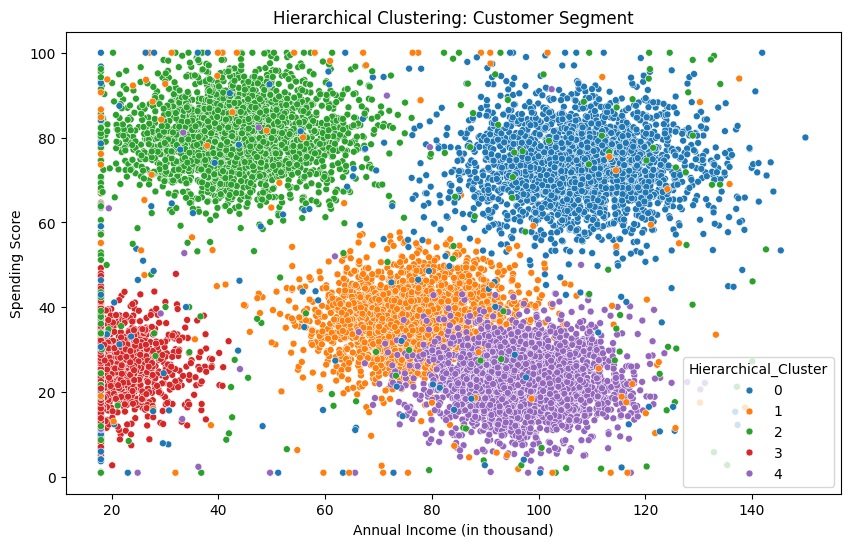

In [9]:
# plot customer cluster using income and spending score 
# import matplotlib
import matplotlib.pyplot as plt 

plt.figure(figsize=(10,6))

sns.scatterplot(
    x= df['Annual_Income_k'],
    y= df['Spending_Score'],
    hue=df['Hierarchical_Cluster'],
    palette='tab10',
    s=25
)

plt.title('Hierarchical Clustering: Customer Segment')
plt.xlabel('Annual Income (in thousand)')
plt.ylabel('Spending Score')
plt.show()

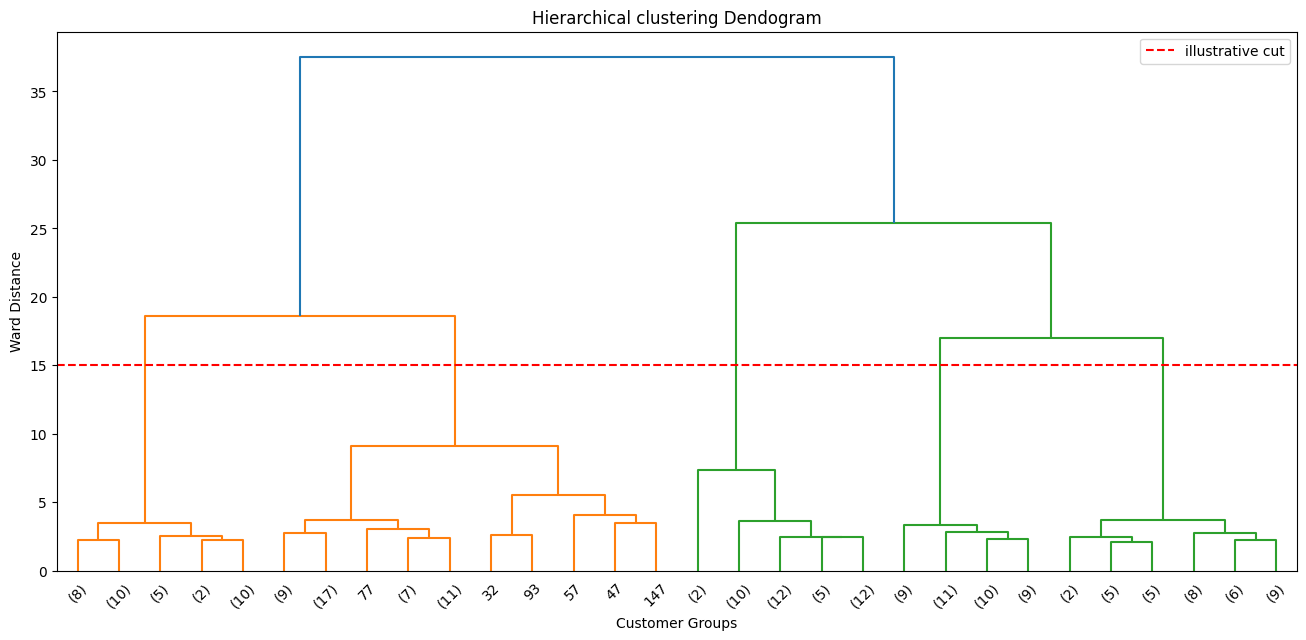

In [10]:
from scipy.cluster.hierarchy import dendrogram, linkage

# select 200 customer for a readable dendrogram
sample = df.sample(n=200, random_state=42)

# select the standardize their numerical features 
x_sample = sample.drop('Customer_ID', axis=1)
x_sample_scaled= StandardScaler().fit_transform(x_sample)

# perform hirerachical clutering using ward linkage 

linked = linkage(x_sample_scaled, method='ward')

# plot the dendrogram

plt.figure(figsize=(16,7))

dendrogram( linked, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Hierarchical clustering Dendogram')
plt.xlabel('Customer Groups')
plt.ylabel('Ward Distance')

plt.axhline(y=15, color='red', linestyle='--', label='illustrative cut')
plt.legend()






## DBSCAN clustering

DBSCAN identifies dense customer groups and marks outliers as noise (`-1`). Compare several `eps` values using the existing standardized features. `min_samples` is fixed at 5 for this comparison.

In [11]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_values = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]
min_samples = 5
dbscan_results = []

for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(x_scale)
    cluster_labels = set(labels) - {-1}
    non_noise = labels != -1
    silhouette = None

    if len(cluster_labels) > 1:
        silhouette = silhouette_score(
            x_scale[non_noise],
            labels[non_noise],
            sample_size=min(2000, non_noise.sum()),
            random_state=42,
        )

    cluster_sizes = pd.Series(labels[non_noise]).value_counts().sort_values(ascending=False).tolist()
    dbscan_results.append({
        'eps': eps,
        'clusters': len(cluster_labels),
        'noise (%)': round((~non_noise).mean() * 100, 2),
        'cluster sizes': cluster_sizes,
        'silhouette (sampled)': round(silhouette, 3) if silhouette is not None else None,
    })

pd.DataFrame(dbscan_results)

,eps,clusters,noise (%),cluster sizes,silhouette (sampled)
0,0.50,7,10.92,"[2259, 2226, 2153, 2062, 1982, 5, 2]",0.607
1,0.75,3,4.16,"[6893, 2307, 2301]",0.448
2,1.00,3,3.75,"[6932, 2309, 2309]",0.441
3,1.25,3,3.22,"[6972, 4637, 5]",0.391
4,1.50,3,2.39,"[11705, 4, 4]",0.205
5,2.00,1,0.28,[11966],NaN


At `eps=0.75`, DBSCAN finds three substantial groups and marks a small fraction of customers as noise. This is a useful visualization starting point; larger `eps` values eventually merge groups.

Cluster counts (including -1 for noise):
DBSCAN_Cluster
-1     499
 0    2307
 1    6893
 2    2301
Name: count, dtype: int64


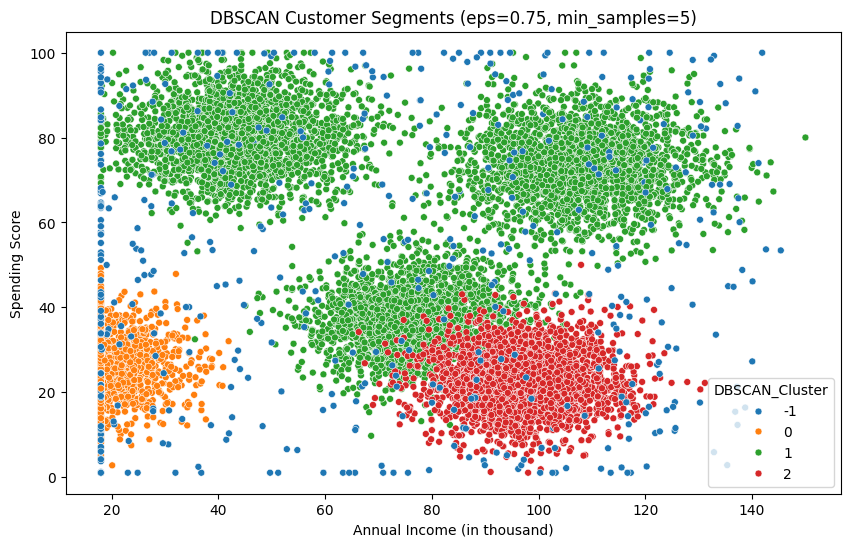

In [12]:
selected_eps = 0.75
dbscan = DBSCAN(eps=selected_eps, min_samples=min_samples)
df['DBSCAN_Cluster'] = dbscan.fit_predict(x_scale)

print('Cluster counts (including -1 for noise):')
print(df['DBSCAN_Cluster'].value_counts().sort_index())

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df['Annual_Income_k'],
    y=df['Spending_Score'],
    hue=df['DBSCAN_Cluster'],
    palette='tab10',
    s=25,
)
plt.title(f'DBSCAN Customer Segments (eps={selected_eps}, min_samples={min_samples})')
plt.xlabel('Annual Income (in thousand)')
plt.ylabel('Spending Score')
plt.show()